In [1]:
from pathlib import Path
import pandas as pd

# File paths
files = {
    "CSV": Path("orders.csv"),
    "JSON": Path("orders.json"),
    "Parquet": Path("orders.parquet")
}

# Compare file sizes
results = []

for format_name, file_path in files.items():
    if file_path.exists():
        size_bytes = file_path.stat().st_size

        results.append({
            "Format": format_name,
            "Size (KB)": round(size_bytes / 1024, 2),
            "Size (MB)": round(size_bytes / (1024 ** 2), 3)
        })
    else:
        print(f"File not found: {file_path}")

comparison = pd.DataFrame(results)
display(comparison)

# Calculate storage savings
sizes = comparison.set_index("Format")["Size (KB)"]

if {"CSV", "JSON", "Parquet"}.issubset(sizes.index):
    csv_saving = (1 - sizes["Parquet"] / sizes["CSV"]) * 100
    json_saving = (1 - sizes["Parquet"] / sizes["JSON"]) * 100

    print(f"Parquet is {csv_saving:.2f}% smaller than CSV.")
    print(f"Parquet is {json_saving:.2f}% smaller than JSON.")

,Format,Size (KB),Size (MB)
0,CSV,480.97,0.470
1,JSON,1877.39,1.833
2,Parquet,105.98,0.103


Parquet is 77.97% smaller than CSV.
Parquet is 94.35% smaller than JSON.


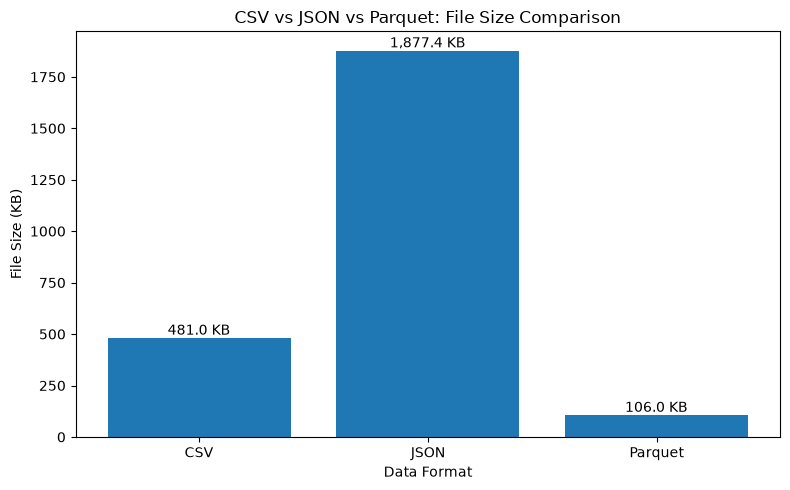

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(comparison["Format"], comparison["Size (KB)"])

plt.title("CSV vs JSON vs Parquet: File Size Comparison")
plt.xlabel("Data Format")
plt.ylabel("File Size (KB)")

for i, size in enumerate(comparison["Size (KB)"]):
    plt.text(i, size, f"{size:,.1f} KB", ha="center", va="bottom")

plt.tight_layout()
plt.savefig("format_comparison.png", dpi=200, bbox_inches="tight")
plt.show()